# OEAS805 Homework 3
## Machine Learning: Regression 

### Objective
Compare three machine learning regression techniques to predict a water-quality variable using environmental measurements from the Chesapeake Bay.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

# Linear model and basic functions from scikit-learn
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Specific models beyond linear regression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import RadiusNeighborsRegressor

In [2]:
# Load the dataset
df = pd.read_csv(r'C:\Users\laure\OEAS805\HW3\data\CBP_TWQM_MAIN_WQ_2021_2026_surface.csv')

df.head()

,Station,FieldActivityId,Cruise,Program,Project,DataCollector,DataProvider,Latitude,Longitude,SampleDate,...,Qualifier,MeasureValue,MeasureUnit,Method,Lab,Problem,PrecisionPC,BiasPC,Details,TierLevel
0,CB4.1C,785801,BAY900,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-11-18,...,NaN,11.000,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
1,CB4.1C,785781,BAY898,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-10-06,...,NaN,7.049,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
2,CB4.1C,785724,BAY895,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-08-26,...,NaN,7.156,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
3,CB4.1C,785723,BAY894,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-08-06,...,NaN,15.620,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
4,CB4.1C,785680,BAY893,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-07-21,...,NaN,38.662,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3


In [3]:
# Look at all column names
print(df.columns.tolist())

['Station', 'FieldActivityId', 'Cruise', 'Program', 'Project', 'DataCollector', 'DataProvider', 'Latitude', 'Longitude', 'SampleDate', 'SampleTime', 'TotalDepthM', 'UpperPycnoclineDepthM', 'LowerPycnoclineDepthM', 'SampleDepthM', 'Layer', 'SampleType', 'SampleReplicate', 'Parameter', 'Qualifier', 'MeasureValue', 'MeasureUnit', 'Method', 'Lab', 'Problem', 'PrecisionPC', 'BiasPC', 'Details', 'TierLevel']


In [4]:
# Look at the available water quality parameters
print(df['Parameter'].unique())

<ArrowStringArray>
[    'CHLA',      'DIN',       'DO',      'DON',      'DOP',       'KD',
     'NH4F',    'NO23F',     'NO2F',     'NO3F',       'PC',       'PH',
     'PHEO',       'PN',     'PO4F',       'PP', 'SALINITY',   'SECCHI',
  'SIGMA_T',   'SPCOND',      'TDN',      'TDP',       'TN',      'TON',
       'TP',      'TSS',    'WTEMP']
Length: 27, dtype: str


## My target variable selection 
I selected dissolved oxygen as my target because it is an important indicator of water quality and oxygen availability for aquatic organisms. I chose water temeprature, salinity, and chlorophyll-a as predictors. Temperature and salinity influence oxygen solubility. Warmer waters and more saline waters will have less oxygen held in them. Chlorophyll will indicate phytoplanktyon biomass which is also connected to O2 production through photosynthesis and O2 consumption through respiration. 


In [5]:
# Put measurements from the same sampling event into one row
data = df[df['Parameter'].isin(['CHLA', 'SALINITY', 'WTEMP', 'DO'])].pivot(
    index=['Station', 'FieldActivityId', 'SampleDepthM'],
    columns='Parameter',
    values='MeasureValue'
)

# Keep samples with all three measurements
data = data.dropna(subset=['CHLA', 'SALINITY', 'WTEMP', 'DO'])

data.head()

Parameter                               CHLA    DO  SALINITY  WTEMP
Station FieldActivityId SampleDepthM                               
CB4.1C  608240          0.5            7.595   7.3      8.31   23.3
        608260          0.5           17.444  10.4      9.33   12.8
        608274          0.5           12.935  10.2     11.87    9.2
        611589          0.5           20.292  11.9      9.33    6.6
        621061          0.5           37.380  14.4      6.49   18.1

In [6]:

# define the inputs and the targets for the machine
X = data[['SALINITY', 'CHLA', 'WTEMP']].to_numpy()
y = data['DO'].to_numpy()

print(X.shape, y.shape)

(42, 3) (42,)


In [7]:
# Split the data into training/testing sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

# Ordinary Least Squares Linear Regression

In [8]:
# Create linear regression object
regr = linear_model.LinearRegression()

# Train the model using the training sets
regr.fit(X_train, y_train)

# Make predictions using the testing set
y_pred = regr.predict(X_test)

In [9]:
# Evaluate model performance:
# The coefficients of the line y_pred = m * X_test + b
print('DO = %.2f * SALINITY + %.2f* CHLA + %.2f* WTEMP + %.2f' % (regr.coef_[0], regr.coef_[1], regr.coef_[2], regr.intercept_))
# The mean squared error (lower numbers, better accuracy)
print('Mean squared error: %.2f'
      % mean_squared_error(y_test, y_pred))
# The coefficient of determination: 1 is perfect prediction
print('Coefficient of determination (R-squared): %.2f'
      % r2_score(y_test, y_pred))

DO = -0.07 * SALINITY + 0.05* CHLA + -0.19* WTEMP + 13.11
Mean squared error: 1.49
Coefficient of determination (R-squared): 0.65


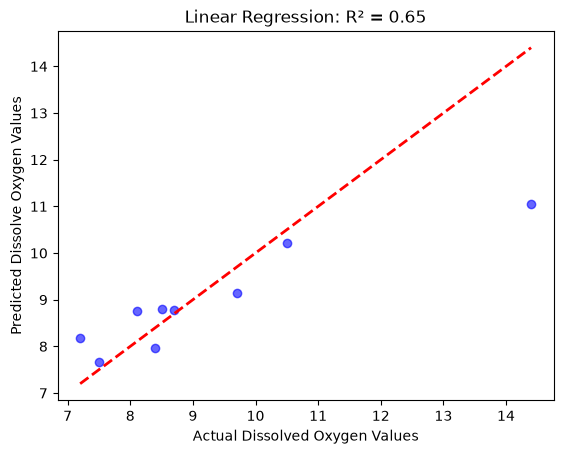

In [16]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # 1:1 reference line
plt.xlabel('Actual Dissolved Oxygen Values')
plt.ylabel('Predicted Dissolve Oxygen Values')
plt.title('Linear Regression: R² = %.2f'
          % regr.score(X_test, y_test))
plt.show()

# K-Nearest Neighbors (KNN) Regression

Choose a number for k:  8


R-squared score: 0.47
Mean squared error: 2.28


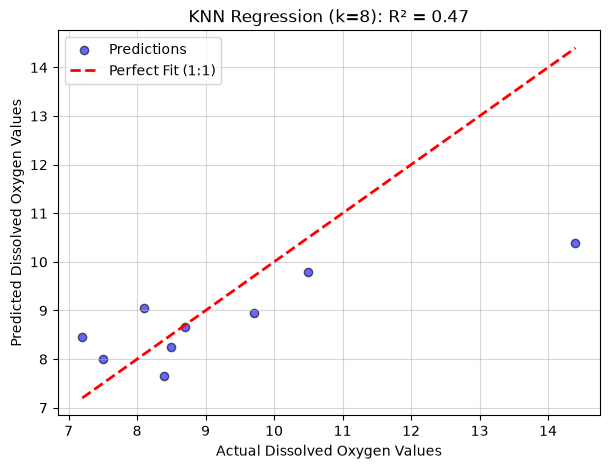

In [31]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

k = int(input('Choose a number for k: '))

# Combine scaling and KNN model into a single pipeline
model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))

# Fit pipeline on unscaled training data (scaler fits automatically)
model.fit(X_train, y_train)

# Generate predictions (scaler transforms X_test automatically)
y_pred_knn = model.predict(X_test)

# Print metrics
print("R-squared score: {0:.2f}".format(model.score(X_test, y_test)))
print("Mean squared error: {0:.2f}".format(mean_squared_error(y_test, y_pred_knn)))

# Plot Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_knn, color='blue', alpha=0.6, edgecolors='k', label='Predictions')

# Add a diagonal line representing perfect predictions
min_val = min(y_test.min(), y_pred_knn.min())
max_val = max(y_test.max(), y_pred_knn.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Fit (1:1)')

plt.xlabel('Actual Dissolved Oxygen Values')
plt.ylabel('Predicted Dissolved Oxygen Values')
plt.title('KNN Regression (k=%d): R² = %.2f'
          % (k, model.score(X_test, y_test)))
plt.legend()
plt.grid(True, linestyle='-', alpha=0.5)
plt.show()

# Non-linear Multi-Layer Perceptron (MLP) Regression

Choose a number for hidden nodes:  6


R-squared score: 0.62
Mean squared error: 1.61


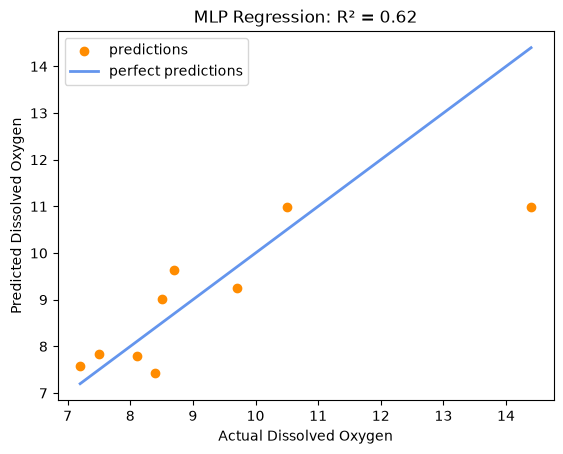

In [34]:
# Choose a number of hidden nodes
n = int(input('Choose a number for hidden nodes: '))

# Fit regression model
regr_1 = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(n,n),
                 activation='tanh',
                 max_iter=10000,
                 random_state=4)
)
regr_1.fit(X_train, y_train)

# Predict
y_1 = regr_1.predict(X_test)

# Evaluate model performance
print("R-squared score: {:.2f}".format(
    regr_1.score(X_test, y_test)))
print("Mean squared error: {:.2f}".format(
    mean_squared_error(y_test, y_1)))

# Plot the results
plt.figure()
plt.scatter(y_test, y_1, c="darkorange", label="predictions")

limits = [min(y_test.min(), y_1.min()),
          max(y_test.max(), y_1.max())]
plt.plot(limits, limits, color="cornflowerblue",
         label="perfect predictions", linewidth=2)

plt.xlabel("Actual Dissolved Oxygen")
plt.ylabel("Predicted Dissolved Oxygen")
plt.title("MLP Regression: R² = %.2f"
          % regr_1.score(X_test, y_test))
plt.legend()
plt.show()

# Model Choices and Comparisons

### Multiple linear regression
Salinity, chlorophyll-a, and water temperature were used to predict the dissolved oxygen values. This model created a baseline linear model and doesnt require a neighbor count ofr a number of nodes to be chosen. This model preformed the best of the three total models (R2 = 0.65 and MSE = 1.49).

### KNN
For the K-nearest neighbors test, I compared a k = 5 and a k = 6 value. Using six neighbors increased the R2 from 0.45 (k = 5) to 0.55, so I seleceted k = 6 for this comparison. Seven neighbors also gave a R2 value of 0.55 and then the values began to decrease when the number of neighbors increased past 7. Using k = 6 means that each prediction averages the dissolved oxygen values of the six nearest training samples. I decided to standardize the predictors so their different units would not affect the distance calcultions (in AI conversation).

### MLP
I tested two hidden layers with either five or six nodes in each layer. Using six nodes per layer gave me bettwe predictions (R2 increased from 0.58 (n = 5) to 0.62 (n = 6). Therefore, the six nodes versiod of the model fit better according the the R-square value. 

I used 'tanh' activation to allow the model to learn nonlinear relationships. Like in the KNN, I standardized the predictors to make sure they wouldnt skew the results and could be used on the same scale. Setting the max_iter = 10000 allowed for 10,000 training tests.  
